# Area and Population of European Countries - Analysis Report

## William Adams

## 11/15/2026

For this Analysis Report, I chose the European Countries JSON Dataset, which can be found at JSONLint.com here : https://jsonlint.com/datasets/european-countries . It is a dataset containing information about different European Countries, with a total of 43 of those countries being present. Each entry contains information about the name, code, capital, population, area in square kilometers, currency, and whether or not each country is a member of the EU. 

I selected this dataset in particular because of a hypothesis I want to explore using certain aspects of this data. I already know that here in America, while the area of a state and the amount of people who live inside of it are usually related, there are far too many outliers for that to be a hard rule, both due to some relatively large states with a relatively small population and some relatively small states with a relatively large population. I would like to use this data in order to find out if the same general relation of population and area exists in Europe as it does in America, as well as to determine how strong or weak that trend is, assuming that it does exist.


In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_json('european-countries.json')
df = pd.DataFrame(data)

display(df.head())
print(df.columns)

,name,code,capital,population,area_km2,eu_member,currency
0,Albania,AL,Tirana,2877797,28748.0,False,ALL
1,Andorra,AD,Andorra la Vella,77265,468.0,False,EUR
2,Austria,AT,Vienna,9006398,83879.0,True,EUR
3,Belarus,BY,Minsk,9449323,207600.0,False,BYN
4,Belgium,BE,Brussels,11589623,30528.0,True,EUR


Index(['name', 'code', 'capital', 'population', 'area_km2', 'eu_member',
       'currency'],
      dtype='str')


Here we can see the different types of data that were mentioned previously organized into this basic table. The population and area_km2 are qualitative, and will be important for deciding the validity of my hypothesis. The numpy and matplotlib.pyplot libraries are also set up here for future use.

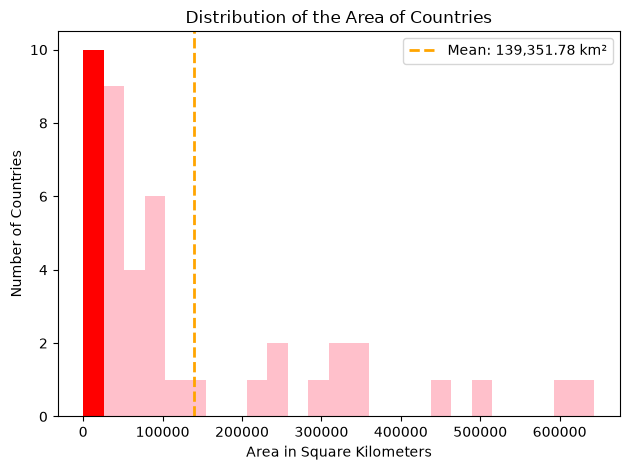

In [60]:
# Defining the mean of all areas here, will be used later.
mean_area = df["area_km2"].mean()

# Base histogram. 
counts, bins, patches = plt.hist(df["area_km2"], bins=25, color='pink')

# Tallest bar highlight (the bar with the most countries).
tallest_bar = np.argmax(counts)
patches[tallest_bar].set_facecolor('red')

# Line that measures the mean of all areas.
plt.axvline(mean_area, color='orange', linestyle='dashed', linewidth=2,
            label=f'Mean: {mean_area:,.2f} km²')

# Title, labels, legend, tight layout.
plt.title("Distribution of the Area of Countries")
plt.xlabel("Area in Square Kilometers")
plt.ylabel("Number of Countries")
plt.legend()
plt.tight_layout()

plt.show()

The distribution of the different countries' areas are represented here as a sharp decline after the 0 - 100000 range. Most European countries are relatively small, with very few breaking 300000 km2. Those few countries that do lie beyond that threshold are clear outliers, with only a few occupying each bracket. Changing the number of bins affects the curve of the chart and the number of individual bars, with fewer making for a less complex histogram with a more consistent downward curve.

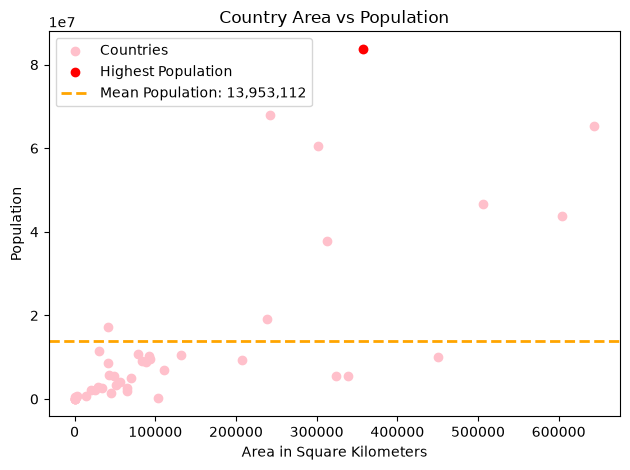

In [61]:
# Defining the mean of population here, will be used later.
mean_population = df["population"].mean()

# Base scatterplot.
plt.scatter(
    df["area_km2"],
    df["population"],
    color='pink',
    label='Countries'
)

# Highest dot highlight (the dot with the most population).
largest_population = df["population"].idxmax()
plt.scatter(
    df.loc[largest_population, "area_km2"],
    df.loc[largest_population, "population"],
    color='red',
    label='Highest Population',
    zorder=3
)

# Line that measures the mean of the population.
plt.axhline(
    mean_population,
    color='orange',
    linestyle='dashed',
    linewidth=2,
    label=f'Mean Population: {mean_population:,.0f}'
)

# Title, labels, legend, tight layout.
plt.title("Country Area vs Population")
plt.xlabel("Area in Square Kilometers")
plt.ylabel("Population")
plt.legend()
plt.tight_layout()

plt.show()

As can be seen in this scatterplot, the relationship between the sizes and the populations of each country has a positive correlation, albeit one of varying strength. The bottom left corner of the graph is where most of the countries are located, with small areas and small populations forming a clear, positive trend. Beyond this space however, the strength of this positive trend begins to diminish. A particular highlight of this phenomena are the countries nearest to the 300000 km2 range, most of which have seemingly random population numbers that have seemingly no correlation to their size.

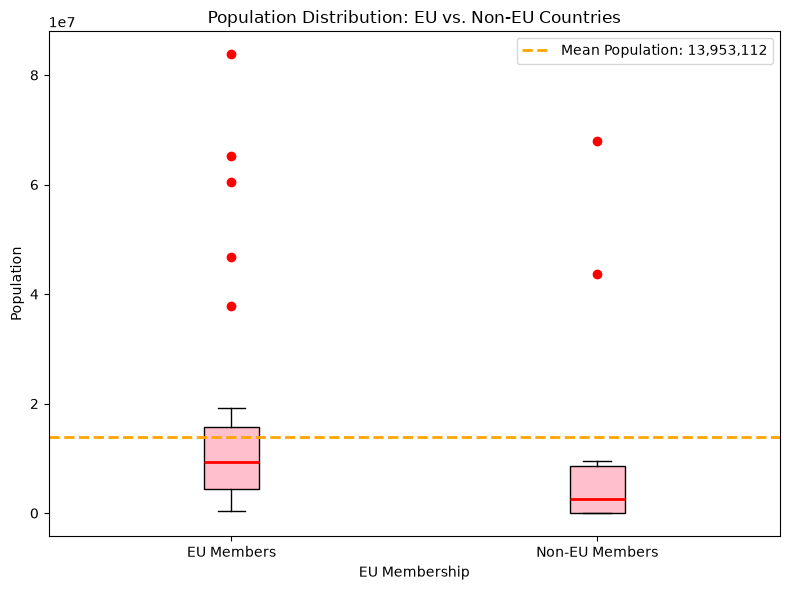

In [62]:
# Defining difference between EU and non-EU members here.
eu_members = df[df['eu_member'] == True]['population'].dropna()
non_eu_members = df[df['eu_member'] == False]['population'].dropna()

# Defining the mean of population here, will be used later.
mean_population = df['population'].mean()

# Base boxplot.
plt.figure(figsize=(8, 6))
boxplot = plt.boxplot(
    [eu_members, non_eu_members],
    tick_labels=['EU Members', 'Non-EU Members'],
    patch_artist=True,
    boxprops=dict(facecolor='pink'),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(markerfacecolor='red', markeredgecolor='red')
)

# Line that measures the mean of the population.
plt.axhline(
    mean_population,
    color='orange',
    linestyle='dashed',
    linewidth=2,
    label=f'Mean Population: {mean_population:,.0f}'
)

# Title, labels, legend, tight layout.
plt.title('Population Distribution: EU vs. Non-EU Countries')
plt.xlabel('EU Membership')
plt.ylabel('Population')
plt.legend()
plt.tight_layout()

plt.show()

In this chart, we can see the differences in population between countries that are a part of the EU compared to those that are not. It seems that EU members have a slightly larger average population than non-EU members. EU members have far more outlier countries with very large populations than non-EU members as well.

While I can see a positive correlation present between size and population in the scatterplot, I will also use a correlation function in order to more accurately determine both the existence and especially the overall strength of that correlation. To do so, I will use the values for the area_km2 and the values for the population in the calculation.

In [57]:
corr_matrix = df['area_km2'].corr(df['population'])
print(corr_matrix)

0.7291848106625124


A correlation score of 0.73 indicates a strong positive relationship between the two variables, thus proving my hypothesis correct. While the relationship is by no means a perfect one, the outliers that are emphasized in the scatterplot are few enough that they do not prove the general rule of population size and area size being related to be false.

This dataset analysis allowed me to learn more about the differing variables of the European countries, particularly the population size and area in square kilometers of each, and how they compare to each-other. My findings did support my initial hypothesis that there is a strong positive correlation between the size and the population of each country, with the scatterplot being the best of the three graphs for allowing me to display this specific correlation. My statistical analysis helped to reinforce my hypothesis as well, allowing me to see a clear measure of the correlation and proving that it is indeed both positive and strong. 

While I am confident in my hypothesis as shown using this dataset, there are several limitations to consider. For one, the dataset captures only a snapshot of each country and is not automatically updated when information about them changes, meaning that the area in square kilometers and especially the population of each country is extremely unlikely to still be completely accurate. The dataset also fails to capture some aspects of these countries that could result in different interpretations of the correlations between variables, such as the rate of immigration / migration or the birthrate of each country. I believe that an alternate version of this dataset with those additional variables added in that could also be updated regularly to keep qualitative information accurate would provide for much more interesting and trustable analysis.